In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib
matplotlib.rcParams['figure.figsize'] = (8, 5)

import warnings
warnings.filterwarnings('ignore')

# Boostings

Данные с которыми вы будете работать представляют из себя характеристики клиента страховой компании по которым нужно понять будет ли он заинтересован в страховке. Таким образом, страховая компания может более оптимально таргетить рекламу и выстраивать коммуникацию с клиентами, повышая конверсию.

**Описания колонок:**
- Gender - Male, Female
- Age - Возраст
- Driving_License - Наличие водительского удостоверения
- Region_Code - Область проживания
- Previously_Insured - Пользовался ли раньше услугами страховой компании
- Vehicle_Age - Возраст транспортного средства
- Vehicle_Damage - Попадало ли траспортное средство в ДТП
- Annual_Premium - Ежегодные выплаты клиента
- Policy_Sales_Channel - Политика распространения страховых услуг (через посредников, напрямую и т.д.)
- Vintage - Количество дней, в течение которых клиент был связан с компанией 


- **Response** - заинтересован в страховке 1, не откликнулся 0

In [2]:
data = pd.read_csv('vehicle_insurance.csv')

data

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,Female,24,1,37.0,1,< 1 Year,No,21243.0,152.0,21,0
9996,Male,28,1,35.0,1,< 1 Year,No,23589.0,160.0,173,0
9997,Female,27,1,15.0,0,< 1 Year,Yes,33340.0,152.0,207,0
9998,Female,28,1,14.0,1,< 1 Year,No,25426.0,152.0,247,0


**Задание 0.** Проведите небольшой EDA. Посмотрите на распределения некоторых колонок, на матрицу корреляций. Также проверьте баланс классов и посмотрите на распределение возраста транспортного средства в зависимости от response. \
Закодируйте признаки типа `object` с помощью `one-hot` кодирования.

P.S. некоторые не `object`колонки по смыслу очевидно являются категориальными. Так как мы будем строить ансамбли на основе деревьев, их можно оставить в первоначальном виде.

In [3]:
num_columns = data.select_dtypes(include=["number"]).columns

data[num_columns].corr()[abs(data[num_columns].corr()) > 0.4]

print(data[num_columns].corr())

                           Age  Driving_License  Region_Code  \
Age                   1.000000        -0.081323     0.030638   
Driving_License      -0.081323         1.000000     0.004926   
Region_Code           0.030638         0.004926     1.000000   
Previously_Insured   -0.261456         0.020464    -0.021270   
Annual_Premium        0.081564        -0.014338    -0.012213   
Policy_Sales_Channel -0.576066         0.044335    -0.039733   
Vintage               0.000030         0.002704    -0.008527   
Response              0.113888         0.011263     0.010230   

                      Previously_Insured  Annual_Premium  \
Age                            -0.261456        0.081564   
Driving_License                 0.020464       -0.014338   
Region_Code                    -0.021270       -0.012213   
Previously_Insured              1.000000       -0.005164   
Annual_Premium                 -0.005164        1.000000   
Policy_Sales_Channel            0.224719       -0.123851   
Vin

Из числовых признаков заметная корреляция наблюдается лишь у Policy_Sales_Channel и Age

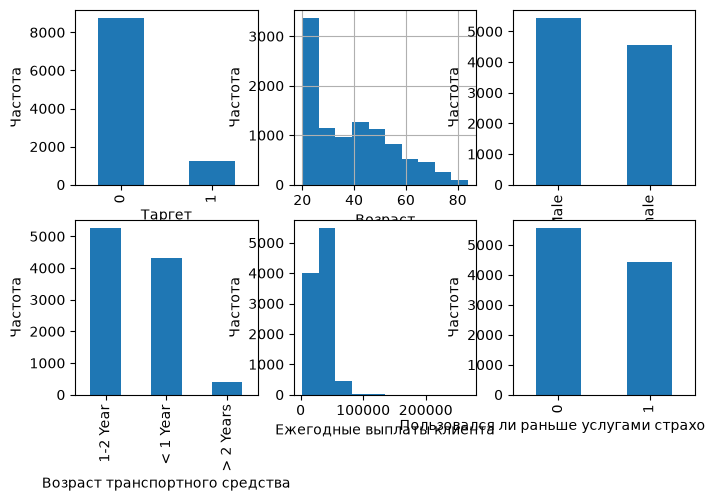

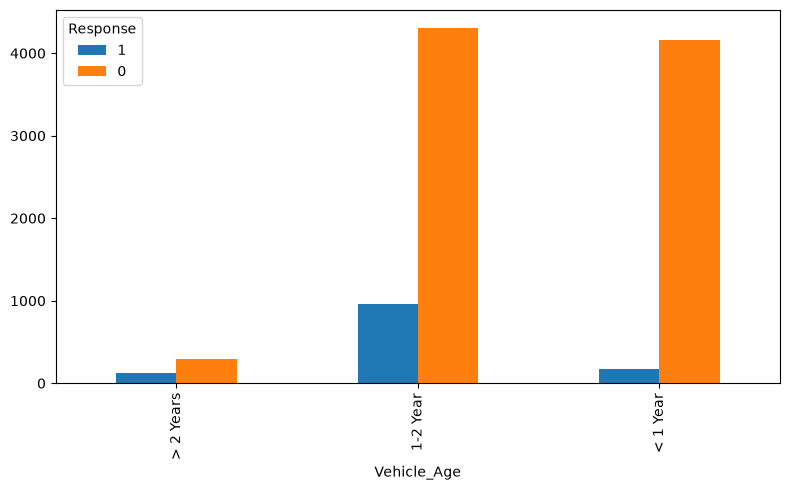

In [4]:
fig, axes = plt.subplots(2, 3)

data['Response'].value_counts().plot(ax=axes[0, 0], kind='bar', xlabel='Таргет', ylabel='Частота')

data['Age'].hist(ax=axes[0, 1])
axes[0, 1].set_xlabel('Возраст')
axes[0, 1].set_ylabel('Частота')

data['Gender'].value_counts().plot(ax=axes[0, 2], kind='bar', xlabel='Пол', ylabel='Частота')

data['Vehicle_Age'].value_counts().plot(
    ax=axes[1, 0], 
    kind='bar', 
    xlabel='Возраст транспортного средства', 
    ylabel='Частота'
)

data['Annual_Premium'].plot(
    ax=axes[1, 1], 
    kind='hist', 
    xlabel='Ежегодные выплаты клиента',
    ylabel='Частота',
    #xlim=(0, 50000),
)

data['Previously_Insured'].value_counts().plot(
    ax=axes[1, 2],
    kind='bar', 
    xlabel='Пользовался ли раньше услугами страховой компании',
    ylabel='Частота',
)

#print(data[['Vehicle_Age', 'Response']])

data[['Vehicle_Age', 'Response']].value_counts().unstack().plot(kind='bar')

plt.tight_layout()

In [5]:
categorical_columns = data.select_dtypes(include=['object']).columns

ohe_cols = pd.get_dummies(data[categorical_columns], drop_first=True)
data = data.drop(categorical_columns, axis=1)
data = pd.concat([data, ohe_cols], axis=1)
print(data)


      Age  Driving_License  Region_Code  Previously_Insured  Annual_Premium  \
0      44                1         28.0                   0         40454.0   
1      76                1          3.0                   0         33536.0   
2      47                1         28.0                   0         38294.0   
3      21                1         11.0                   1         28619.0   
4      29                1         41.0                   1         27496.0   
...   ...              ...          ...                 ...             ...   
9995   24                1         37.0                   1         21243.0   
9996   28                1         35.0                   1         23589.0   
9997   27                1         15.0                   0         33340.0   
9998   28                1         14.0                   1         25426.0   
9999   25                1         45.0                   1         18843.0   

      Policy_Sales_Channel  Vintage  Response  Gend

**Задание 1.** Обучите градиентный бустинг из sklearn на данных и замерьте accuracy и f1-score на тестовой выборке. В качестве параметров ансамбля установите `learning_rate = 1`, `random_state = 1`, `n_estimators = 100`. Изобразите ROC-кривую и посчитайте AUC, оцените качество классификации. (2б)

P.S. для всех прочих моделей в этом домашнем задании тоже фиксируйте `random_state = 1`. Как думаете, что может быть случайного в процедуре обучения градиентного бустинга?

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, roc_curve, auc

X = data.drop('Response', axis=1)
y = data['Response']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state=0,
                                                    shuffle=True,
                                                    test_size=0.2)

ROC AUC: 0.8282399901744043
              precision    recall  f1-score   support

           0       0.90      0.93      0.92      1770
           1       0.31      0.24      0.27       230

    accuracy                           0.85      2000
   macro avg       0.61      0.59      0.59      2000
weighted avg       0.84      0.85      0.84      2000



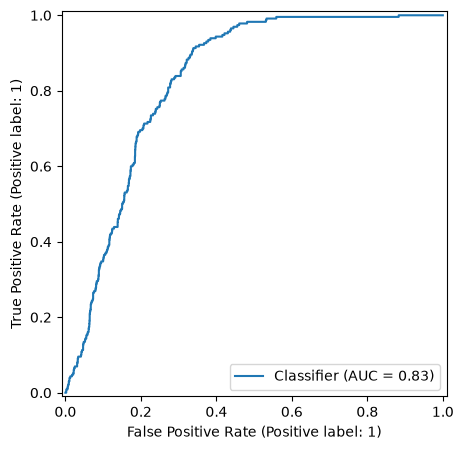

In [7]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import RocCurveDisplay

np.random.seed(1)

gradient_boosting_classifier = GradientBoostingClassifier(
    n_estimators=100, 
    learning_rate=1, 
    random_state=1
)

gradient_boosting_classifier.fit(X_train, y_train)
y_pred = gradient_boosting_classifier.predict(X_test)
y_pred_proba = gradient_boosting_classifier.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

roc_auc = auc(fpr, tpr)
print('ROC AUC:', roc_auc)

RocCurveDisplay.from_predictions(y_test, y_pred_proba)

print(classification_report(y_test, y_pred))

При AUC ≈ 0,828 модель распознаёт положительный класс с F1 ≈ 0,27 и recall ≈ 0,24

**Задание 2.** Переберите параметры `n_estimators` и `learning_rate` по двумерной сетке. При обучении в цикле сразу считайте f1-score на тестовой выборке и сохраняйте результат в матрицу. Для какого алгоритма качество окажется максимальным?

Постройте кривые для метрики f1-score в зависимости от числа шагов для нескольких learning_rate. Изобразите heatmap полученной матрицы. Сделайте вывод, как количество шагов влияет на качество совместно с различной скоростью обучения? (2б)

P.S. для подсчета f1-score передайте в функцию параметр `average='weighted'`, чтобы учитывался еще и баланс классов (вспомните микро/макро-усреднения).

In [8]:
### Задаем сетку параметров

n_estimators_list = [5, 10, 20, 50, 100, 200, 700, 1000]
learning_rate_list = [1, 0.1, 0.01]

0.8452124974550719
[0.17157554 0.00078541 0.04148233 0.05390217 0.19724825 0.08115853
 0.09691135 0.00675152 0.01545813 0.01765716 0.31706961]


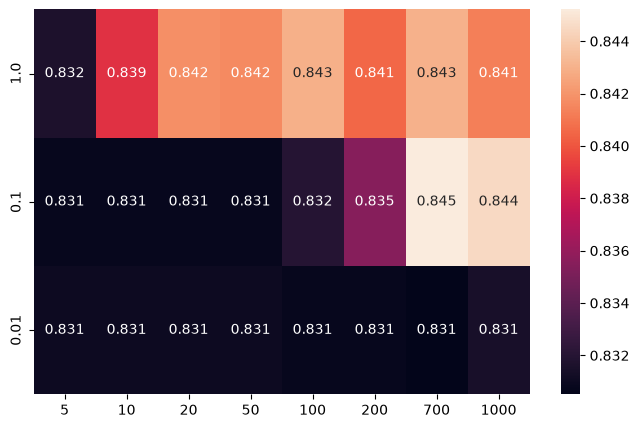

In [9]:
scores = pd.DataFrame(
    index=learning_rate_list,
    columns=n_estimators_list
)

for n_estimators in n_estimators_list:
    for learning_rate in learning_rate_list:
        gradient_boosting_classifier = GradientBoostingClassifier(
            n_estimators=n_estimators, 
            learning_rate=learning_rate,
            random_state=1
        )

        gradient_boosting_classifier.fit(X_train, y_train)
        y_pred = gradient_boosting_classifier.predict(X_test)

        f1 = f1_score(y_test, y_pred, average='weighted')
        scores.loc[learning_rate, n_estimators] = f1

scores = scores.astype('float')
sns.heatmap(scores, annot=True, fmt=".3f")

# Лучшая модель оказалась с гиперпараметрами learning_rate=0.1 и n_estimators=700

best_gradient_boosting_classifier = GradientBoostingClassifier(
    n_estimators=700, 
    learning_rate=0.1,
    random_state=1
)

best_gradient_boosting_classifier.fit(X_train, y_train)
y_pred = best_gradient_boosting_classifier.predict(X_test)

f1 = f1_score(y_test, y_pred, average='weighted')
print(f1)
print(best_gradient_boosting_classifier.feature_importances_)

<Axes: title={'center': 'Зависимость F1 score от n_estimators при фиксированном learning_rate'}, xlabel='n_estimators', ylabel='F1 score'>

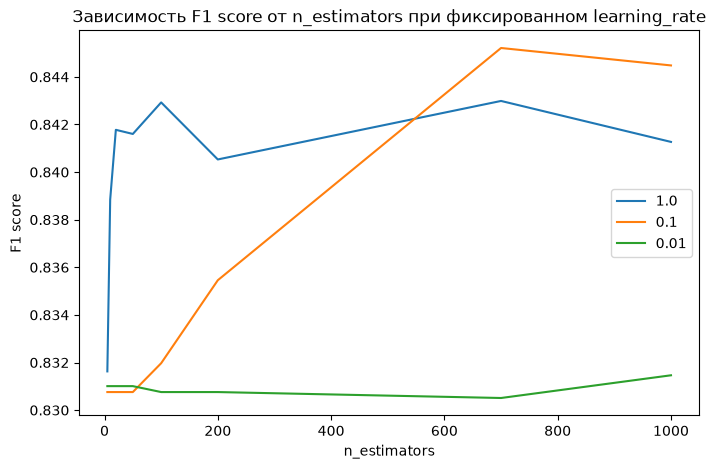

In [10]:
scores.T.plot(
    xlabel='n_estimators', 
    ylabel='F1 score', 
    title='Зависимость F1 score от n_estimators при фиксированном learning_rate'
)

Вывод: При небольшом learning_rate каждое дерево слабо меняет предсказания, поэтому качество растёт медленно и требуется больше деревьев. При большом шаге качество может улучшиться быстрее, но возрастает риск перескочить удачное решение и сильнее подстроиться под шум; при дальнейшем добавлении деревьев качество на новых данных может снизиться. С меньшим шагом изменение качества обычно плавнее, поэтому момент остановки можно выбрать по валидационной выборке с меньшей потерей качества. Следовательно, learning_rate и число деревьев нужно подбирать совместно.

**Задание 3.** Вам потребуется обучить 4 модели и посчитать метрику f1-score на тестовой и обучающей выборках для каждой модели. 
1. Случайный лес с максимальной глубиной деревьев 5,
2. Случайный лес с максимальной глубиной деревьев 5000,
3. Градиентный бустинг с максимальной глубиной деревьев 5,
4. Градиентный бустинг с максимальной глубиной деревьев 5000.

Для каждой модели перебирайте значения `n_estimators`, как в предыдущем задании. Отрисуйте графики зависимости f1-score от количества шагов, используя `average='weighted'` для учёта баланса классов. 

Если в качестве базовой модели брать неглубокие деревья, то какая модель лучше запоминает обучающую выборку: случайный лес или градиентный бустинг? Какая из них лучше предсказывает на тестовой выборке? Как изменятся ответы, если базовая модель - это глубокое решающее дерево?

Подвержен ли переобучению случайный лес и градиентный бустинг? Как это отражается на графиках? (4б)

                                             2         3         4     \
random_forest_depth_5                    0.816024  0.814952  0.813931   
random_forest_depth_5000                 0.935113  0.965297  0.961487   
gradient_boosting_classifier_depth_5     0.813627  0.813627  0.813627   
gradient_boosting_classifier_depth_5000  0.813627  0.813627  0.813627   

                                             5         10        20    \
random_forest_depth_5                    0.814714  0.813627  0.813627   
random_forest_depth_5000                 0.980297  0.986199  0.996608   
gradient_boosting_classifier_depth_5     0.814235  0.815745  0.818435   
gradient_boosting_classifier_depth_5000       1.0       1.0       1.0   

                                             50        70        100   \
random_forest_depth_5                    0.813627  0.813627  0.813627   
random_forest_depth_5000                 0.999374  0.999875       1.0   
gradient_boosting_classifier_depth_5     0.834638

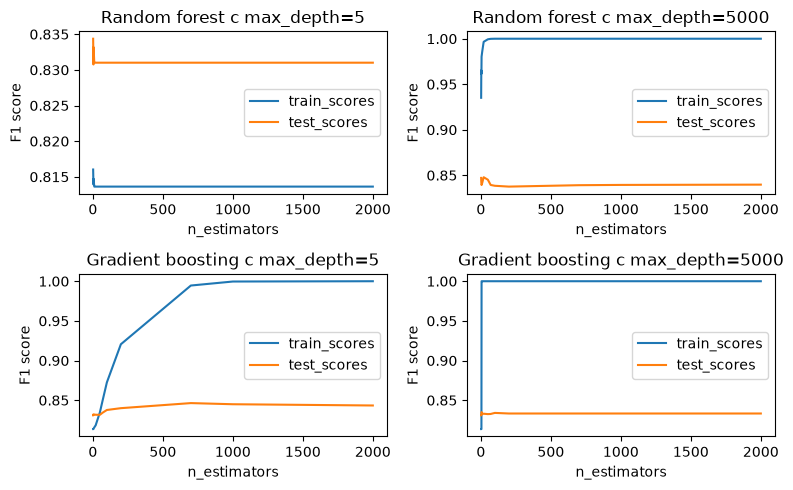

In [11]:
from sklearn.ensemble import RandomForestClassifier

n_estimators_list = [2, 3, 4, 5, 10, 20, 50, 70, 100, 200, 700, 1000, 2000]

train_scores = pd.DataFrame(
    columns=n_estimators_list,
    index=[
        'random_forest_depth_5',
        'random_forest_depth_5000',
        'gradient_boosting_classifier_depth_5',
        'gradient_boosting_classifier_depth_5000'
    ]
)

test_scores = pd.DataFrame(
    columns=n_estimators_list,
    index=[
        'random_forest_depth_5',
        'random_forest_depth_5000',
        'gradient_boosting_classifier_depth_5',
        'gradient_boosting_classifier_depth_5000'
    ]
)

for n_estimators in n_estimators_list:
    random_forest_depth_5 = RandomForestClassifier(
        max_depth=5, 
        n_estimators=n_estimators,
        random_state=1,
        n_jobs=-1
    )

    random_forest_depth_5000 = RandomForestClassifier(
        max_depth=5000, 
        n_estimators=n_estimators,
        random_state=1,
        n_jobs=-1
    )

    gradient_boosting_classifier_depth_5 = GradientBoostingClassifier(
        max_depth=5, 
        n_estimators=n_estimators,
        random_state=1
    )

    gradient_boosting_classifier_depth_5000 = GradientBoostingClassifier(
        max_depth=5000, 
        n_estimators=n_estimators,
        random_state=1
    )

    random_forest_depth_5.fit(X_train, y_train)
    random_forest_depth_5000.fit(X_train, y_train)
    gradient_boosting_classifier_depth_5.fit(X_train, y_train)
    gradient_boosting_classifier_depth_5000.fit(X_train, y_train)


    y_pred_random_forest_depth_5_train = random_forest_depth_5.predict(X_train)
    y_pred_random_forest_depth_5_test = random_forest_depth_5.predict(X_test)

    train_scores.loc['random_forest_depth_5', n_estimators] = f1_score(
        y_train, 
        y_pred_random_forest_depth_5_train,
        average='weighted'
    )
    test_scores.loc['random_forest_depth_5', n_estimators] = f1_score(
        y_test, 
        y_pred_random_forest_depth_5_test,
        average='weighted'
    )



    y_pred_random_forest_depth_5000_train = random_forest_depth_5000.predict(X_train)
    y_pred_random_forest_depth_5000_test = random_forest_depth_5000.predict(X_test)

    train_scores.loc['random_forest_depth_5000', n_estimators] = f1_score(
        y_train, 
        y_pred_random_forest_depth_5000_train,
        average='weighted'
    )
    test_scores.loc['random_forest_depth_5000', n_estimators] = f1_score(
        y_test, 
        y_pred_random_forest_depth_5000_test,
        average='weighted'
    )


    y_pred_gradient_boosting_depth_5_train = gradient_boosting_classifier_depth_5.predict(X_train)
    y_pred_gradient_boosting_depth_5_test = gradient_boosting_classifier_depth_5.predict(X_test)

    train_scores.loc['gradient_boosting_classifier_depth_5', n_estimators] = f1_score(
        y_train, 
        y_pred_gradient_boosting_depth_5_train,
        average='weighted'
    )
    test_scores.loc['gradient_boosting_classifier_depth_5', n_estimators] = f1_score(
        y_test, 
        y_pred_gradient_boosting_depth_5_test,
        average='weighted'
    )



    y_pred_gradient_boosting_depth_5000_train = gradient_boosting_classifier_depth_5000.predict(X_train)
    y_pred_gradient_boosting_depth_5000_test = gradient_boosting_classifier_depth_5000.predict(X_test)

    train_scores.loc['gradient_boosting_classifier_depth_5000', n_estimators] = f1_score(
        y_train, 
        y_pred_gradient_boosting_depth_5000_train,
        average='weighted'
    )
    test_scores.loc['gradient_boosting_classifier_depth_5000', n_estimators] = f1_score(
        y_test, 
        y_pred_gradient_boosting_depth_5000_test,
        average='weighted'
    )


fig, ax = plt.subplots(2, 2)

ax[0, 0].plot(
    n_estimators_list, 
    train_scores.loc['random_forest_depth_5'].values, 
    label='train_scores'
)
ax[0, 0].plot(
    n_estimators_list, 
    test_scores.loc['random_forest_depth_5'].values, 
    label='test_scores'
)
ax[0, 0].set_xlabel('n_estimators')
ax[0, 0].set_ylabel('F1 score')
ax[0, 0].set_title('Random forest с max_depth=5')



ax[0, 1].plot(
    n_estimators_list, 
    train_scores.loc['random_forest_depth_5000'].values, 
    label='train_scores'
)
ax[0, 1].plot(
    n_estimators_list, 
    test_scores.loc['random_forest_depth_5000'].values, 
    label='test_scores'
)
ax[0, 1].set_xlabel('n_estimators')
ax[0, 1].set_ylabel('F1 score')
ax[0, 1].set_title('Random forest с max_depth=5000')



ax[1, 0].plot(
    n_estimators_list, 
    train_scores.loc['gradient_boosting_classifier_depth_5'].values, 
    label='train_scores'
)
ax[1, 0].plot(
    n_estimators_list, 
    test_scores.loc['gradient_boosting_classifier_depth_5'].values, 
    label='test_scores'
)
ax[1, 0].set_xlabel('n_estimators')
ax[1, 0].set_ylabel('F1 score')
ax[1, 0].set_title('Gradient boosting с max_depth=5')



ax[1, 1].plot(
    n_estimators_list, 
    train_scores.loc['gradient_boosting_classifier_depth_5000'].values, 
    label='train_scores'
)
ax[1, 1].plot(
    n_estimators_list, 
    test_scores.loc['gradient_boosting_classifier_depth_5000'].values, 
    label='test_scores'
)
ax[1, 1].set_xlabel('n_estimators')
ax[1, 1].set_ylabel('F1 score')
ax[1, 1].set_title('Gradient boosting с max_depth=5000')


ax[0, 0].legend()
ax[0, 1].legend()
ax[1, 0].legend()
ax[1, 1].legend()

print(train_scores)
print(test_scores)

fig.tight_layout()

print(test_scores.max().max())

<Axes: >

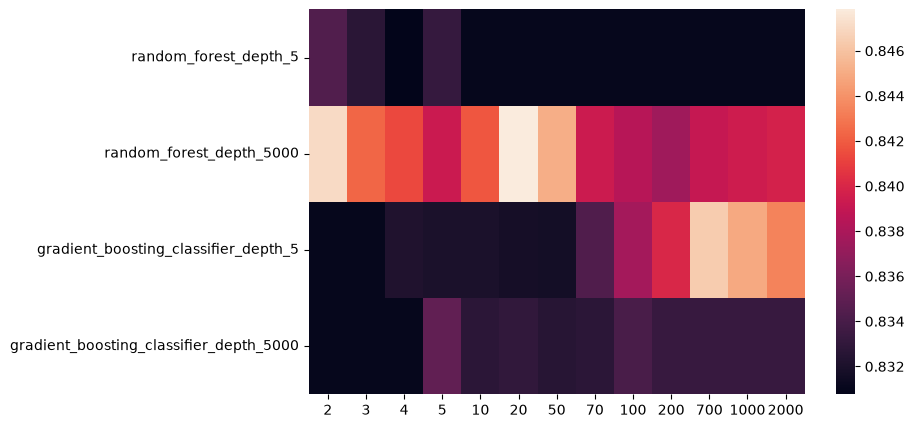

In [12]:
sns.heatmap(test_scores.astype('float'))

Видно, что у глубокого случайного леса самое большое качество на тестовой выборке. Здесь она выигрывает градиентный бустинг. Но в случае неглубоких деревьев градиентный бустинг заметно лучше. Запоминают тренировочную выборку обе модели с глубокими деревьями практически одинаково, но градиентный бустинг делает это быстрее. При неглубоких деревьях градиентный бустинг лучше запоминает тренировочную выборку. Также видно, что модели подвержены переобучению: обе модели с глубокими деревьями сильно переобучились, но градиентный бустинг переобучился заметно быстрее. Random forest с неглубокими деревьями практически не переобучился, а вот градиентный бустинг с неглубокими деревьями переобучился сильно, особенно при большом количестве деревьев.

**Задание 4.** Установите библиотеку `catboost`. Главной особенностью catboost явялется наличие встроенной обработки категориальных признаков. Для каждого категориального столбца вычисляется следующее значение
$$
avg\_target = \dfrac{countInClass + prior}{totalCount + 1},
$$
* countInClass - количество объектов положительного класса для данной категории **до текущего объекта**,
* prior - некоторая константа для числителя, обычно равна доле положительного класса в таргете,
* totalCount - количество наблюдаемых категорий вплоть **до текущего** с той же категорией, что и у текущего.

Так как первые такие значения будут иметь больший разброс, чем последние, то выборку перемешивают несколько раз и полученные статистики усредняют. 
В отличие от target encoder подсчитанные значения зависят от наблюдаемой истории, т.е. вычисляются только из наблюдений до них, таким образом не происходит target leakage. 

Почитать подробнее можно здесь: [Transforming categorical features](https://catboost.ai/en/docs/concepts/algorithm-main-stages_cat-to-numberic)

Обучите CatBoostClassifier с дефолтными параметрами. Используйте датасет до  (разбейте на train/test по старой логике с тем же random state'ом). Категориальные колонки передайте в параметр `cat_features` метода `fit`. Catboost сам с ними разберется.

Сравните качество с моделью из предыдущего задания. Стало ли лучше?

Сравните feature importances в модели из задания 2 и в catboost с помощью соответствующих методов, изобразите их, используя `barplot`. \
Какие признаки стали более важными с новым методом кодирования? (4б)

Learning rate set to 0.025035
0:	learn: 0.6585225	total: 52.7ms	remaining: 52.7s
1:	learn: 0.6268982	total: 56.2ms	remaining: 28.1s
2:	learn: 0.5928588	total: 59.6ms	remaining: 19.8s
3:	learn: 0.5650766	total: 62.7ms	remaining: 15.6s
4:	learn: 0.5422486	total: 66.1ms	remaining: 13.2s
5:	learn: 0.5180757	total: 71.2ms	remaining: 11.8s
6:	learn: 0.4967701	total: 74.9ms	remaining: 10.6s
7:	learn: 0.4783631	total: 77.9ms	remaining: 9.66s
8:	learn: 0.4615549	total: 81.6ms	remaining: 8.98s
9:	learn: 0.4527304	total: 84.8ms	remaining: 8.4s
10:	learn: 0.4445958	total: 88ms	remaining: 7.91s
11:	learn: 0.4300633	total: 91.8ms	remaining: 7.55s
12:	learn: 0.4153701	total: 95.5ms	remaining: 7.25s
13:	learn: 0.4046506	total: 98.7ms	remaining: 6.95s
14:	learn: 0.3953227	total: 103ms	remaining: 6.74s
15:	learn: 0.3908375	total: 106ms	remaining: 6.53s
16:	learn: 0.3866243	total: 110ms	remaining: 6.34s
17:	learn: 0.3780907	total: 113ms	remaining: 6.17s
18:	learn: 0.3711807	total: 117ms	remaining: 6.02s


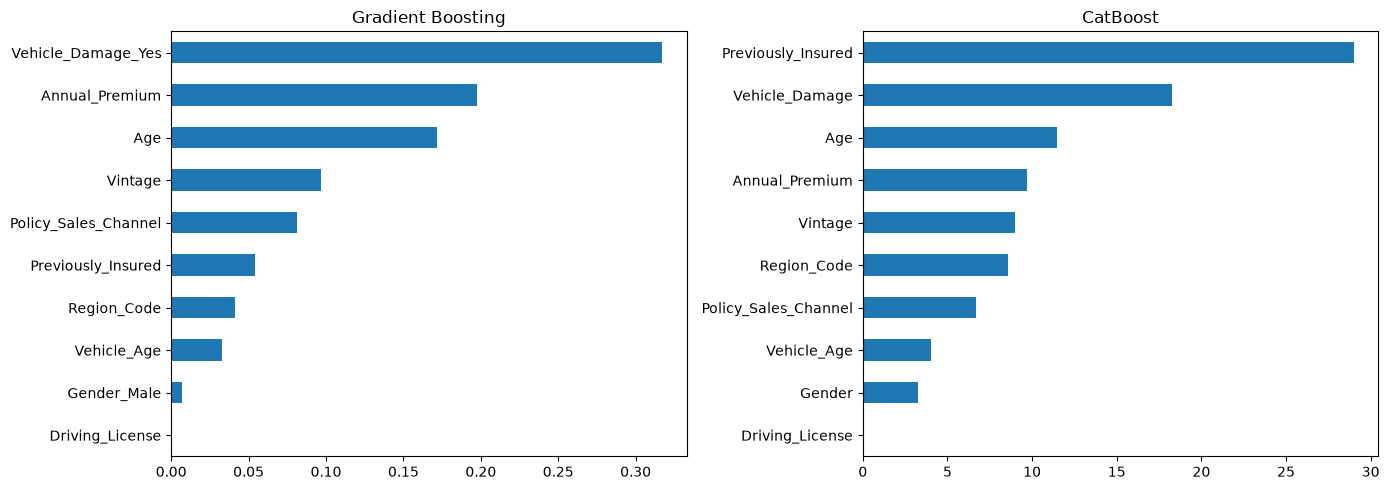

In [13]:
from catboost import CatBoostClassifier

df_catboost = pd.read_csv('vehicle_insurance.csv')

X_catboost = df_catboost.drop('Response', axis=1)
y_catboost = df_catboost['Response']

X_train_catboost, X_test_catboost, y_train_catboost, y_test_catboost = train_test_split(
    X_catboost,
    y_catboost,
    test_size=0.2,
    shuffle=True,
    random_state=0
)

catboostclassifier = CatBoostClassifier(random_state=1)
catboostclassifier.fit(X_train_catboost, y_train_catboost, cat_features=categorical_columns.to_list())

#print(best_gradient_boosting_classifier.feature_importances_)

gb_importances = pd.Series(
    best_gradient_boosting_classifier.feature_importances_,
    index=best_gradient_boosting_classifier.feature_names_in_
)

vehicle_age_importance = gb_importances[
    gb_importances.index.str.startswith("Vehicle_Age")
].sum()

gb_importances = gb_importances[
    ~gb_importances.index.str.startswith("Vehicle_Age")
]

gb_importances["Vehicle_Age"] = vehicle_age_importance

gb_importances = gb_importances.sort_values(ascending=False)

cat_importances = pd.Series(
    catboostclassifier.feature_importances_,
    index=X_train_catboost.columns
).sort_values(ascending=False)

print(gb_importances)
print(cat_importances)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gb_importances.sort_values().plot(
    kind="barh",
    ax=axes[0],
    title="Gradient Boosting"
)

cat_importances.sort_values().plot(
    kind="barh",
    ax=axes[1],
    title="CatBoost"
)

print(f1_score(y_test_catboost, catboostclassifier.predict(X_test_catboost), average='weighted'))

plt.tight_layout()
plt.show()

CatBoost дал f1 score 0.8405, а обычный градиентный бустинг из sklearn дал 0.845, то есть CatBoost показал результат хуже на 0,0047. С новым методом кодирования стал важнее признак Previously_Insured. 

**Задание 5.** Установите библиотеку `lightgbm`. На сегодняшний день это наиболее быстрый метод градиентного бустинга, при этом расходующий небольшое количество оперативной памяти. Достигает он этого за счет построения деревьев вглубь по листьям (leaf-wise), а не по уровням (level-wise), как другие методы, например XGBoost. 
Более понятно это на картинке:

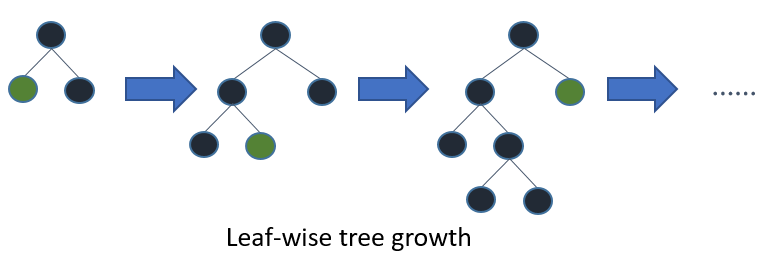

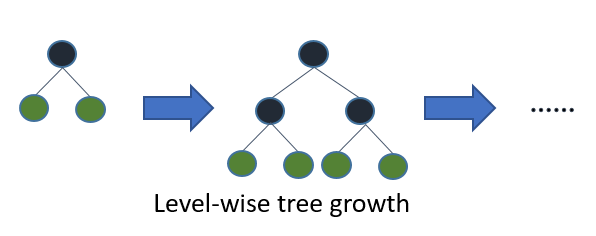

В то время, как XGBoost за раз разделяет вершины на целом уровне той же глубины, LightGBM разделяет одну вершину за раз. Отсюда прирост в скорости.

Обучите `LGBMClassifier` на изначальных(закодированных) данных и добейтесь максимального качества на тестовой выборке, перебрав параметры глубины деревьев, количества шагов, скорости обучения и т.д.

In [14]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV

params = {'n_estimators': [100, 500, 1000, 2000],
          'max_depth': [2, 3, 5, 100],
          'learning_rate': [0.1, 0.01, 0.001]}

search = GridSearchCV(LGBMClassifier(random_state=1, verbose=-1), params)

search.fit(X_train, y_train)

print(search.best_params_)
# print(search.best_score_)

print(classification_report(y_test, search.predict(X_test)))


{'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      1770
           1       0.00      0.00      0.00       230

    accuracy                           0.89      2000
   macro avg       0.44      0.50      0.47      2000
weighted avg       0.78      0.89      0.83      2000

